# W3D3 — Backpropagation with Autograd — Lab

**Week 3 · Day 3 · Deep Learning & Neural Networks** · Lab

This is the hardest lab of the bootcamp, and the one that pays for the rest of it. A student who
finishes task 2.3 knows what PyTorch's autograd is doing on their behalf — and, more usefully,
knows how to check whether it is doing it correctly.

Four things, in order:

- **Measure a gradient.** Nudge one weight by 0.01, run the forward pass again, divide the change in
  loss by the change in the weight. That is the whole idea, and it is the lecture's `−0.134`.
- **Write the loss.** Binary cross-entropy, on two predictions of the same true label, and the ratio
  between them: 22, not 2.
- **Let autograd do the backward pass** — mark the parameters, call `loss.backward()`, read
  `.grad` — and then **check every single gradient against the numerical one.** Not one of them.
  All 33. This is the task; protect its time.
- **Train it.** 2,000 iterations, a loss curve that falls, and a decision boundary that curves around
  a moon — beside yesterday's smear, in the same figure.

You leave with `tensor_net_history.parquet` and `tensor_net_params.pt`. Tomorrow `nn.Module` and
`torch.optim` reproduce both, from the same starting weights, to six decimals.

**Time budget:** ~115 minutes. Sections 1–2 are the lab; Section 3 is a stretch you may finish at home.

<div dir="rtl" align="right">

# الأسبوع ٣ اليوم ٣ — الانتشار الخلفي بالاشتقاق التلقائي

**الأسبوع ٣ · اليوم ٣ · التعلّم العميق والشبكات العصبية** · معمل عملي

هذا أصعب معامل في المعسكر، وهو الذي يدفع ثمن بقيتها. والطالب الذي يُكمل المهمة ٢٫٣ يعرف ما يفعله عنه
الاشتقاق التلقائي (autograd) في PyTorch — والأنفع أنه يعرف كيف يتحقّق أنه يفعله بصواب.

وأربعة أمور بالترتيب:

- **قِس اشتقاقًا.** حرّك وزنًا واحدًا بمقدار ٠٫٠١، وأعِد المرور الأمامي، واقسم تغيّر الخسارة على
  تغيّر الوزن. هذه هي الفكرة كلها، وهي `−0.134` في المحاضرة.
- **اكتب دالة الخسارة.** الانتروبيا التقاطعية الثنائية على تنبّؤين للتصنيف الصحيح نفسه، والنسبة
  بينهما: ٢٢ لا ٢.
- **دع الاشتقاق التلقائي يُجري المرور الخلفي** — علّم المعاملات، ونادِ `loss.backward()`، واقرأ
  `.grad` — ثم **افحص كل اشتقاق مقابل نظيره العددي.** لا واحدًا منها بل الثلاثة والثلاثين كلها.
  وهذه هي المهمة، فاحمِ وقتها.
- **درّبها.** ألفا تكرار ومنحنى خسارة يهبط وحدّ قرار ينحني حول هلال — بجانب لطخة الأمس في الشكل نفسه.

ستخرج بملفَّي `tensor_net_history.parquet` و`tensor_net_params.pt`. وغدًا يُعيد `nn.Module` و`torch.optim`
إنتاجهما من الأوزان الابتدائية نفسها إلى ست خانات عشرية.

**الزمن المتوقّع:** نحو ١١٥ دقيقة. القسمان الأول والثاني هما المعمل، والقسم الثالث إضافي يمكن إكماله في المنزل.

</div>

> **This is your lab notebook.** Work through the hints — they tell you what to do and where
> to look, not what to type. Stuck for more than ten minutes on one task? Open the `_guided`
> version. That is not cheating; sitting stuck in silence is the only mistake. The full
> solution is released at the end of the day.

<div dir="rtl" align="right">

> **هذا دفتر المعمل الخاص بك.** اعمل وفق الإرشادات — فهي تخبرك بما يجب فعله وأين تبحث، لا بما
> تكتبه حرفيًا. إذا توقّفت أكثر من عشر دقائق عند مهمة واحدة فافتح نسخة `_guided`؛ هذا ليس غشًّا،
> والخطأ الوحيد هو أن تبقى متوقّفًا بصمت. ويُنشر الحل الكامل في نهاية اليوم.

</div>

## Learning objectives

By the end of this lab you can:

- Measure the gradient of a loss with respect to one weight by nudging it, and read its sign as a
  direction.
- Say why a central difference is more accurate than a one-sided one, having computed both.
- Implement binary cross-entropy, and say why a confident wrong answer costs 22 times a hesitant one
  rather than twice.
- Get a gradient for every parameter of a two-layer network from autograd, and say what
  `requires_grad_`, `loss.backward()` and `.grad` each do.
- **Verify** autograd's gradients against numerical ones, parameter by parameter — the single most
  useful debugging skill in this course.
- Write a training loop by hand: the update under `torch.no_grad()`, and the gradients cleared
  every step.
- Train a network with gradient descent and read its loss curve.
- Show that your trained network's boundary is non-linear, by beating a fitted logistic regression on
  the same data.
- Say what backpropagation actually saves, as a measured ratio rather than a claim.

<div dir="rtl" align="right">

## أهداف التعلّم

بنهاية هذا المعمل ستكون قادرًا على:

- قياس اشتقاق الخسارة بالنسبة لوزن واحد بتحريكه، وقراءة إشارته كاتجاه.
- بيان لماذا يكون الفرق المركزي أدقّ من الفرق أحادي الجهة، بعد أن حسبت الاثنين.
- تنفيذ الانتروبيا التقاطعية الثنائية، وبيان لماذا يكلّف الجواب الخطأ الواثق ٢٢ ضعف الجواب المتردّد
  لا ضعفين.
- الحصول على اشتقاق لكل معامل في شبكة ذات طبقتين من الاشتقاق التلقائي، وبيان ما يفعله كلٌّ من
  `requires_grad_` و`loss.backward()` و`.grad`.
- **التحقّق** من اشتقاقات الاشتقاق التلقائي مقابل الاشتقاقات العددية، معاملًا معاملًا — وهي أنفع
  مهارة تصحيح في هذه الدورة.
- كتابة حلقة تدريب بيدك: التحديث داخل `torch.no_grad()`، ومسح الاشتقاقات في كل خطوة.
- تدريب شبكة بطريقة النزول التدريجي وقراءة منحنى خسارتها.
- إظهار أن حدّ شبكتك المُدرَّبة غير خطي، بتجاوز انحدار لوجستي مُدرَّب على البيانات نفسها.
- بيان ما يوفّره الانتشار الخلفي فعلًا، كنسبة مقيسة لا كادّعاء.

</div>


## About the data

**Dataset:** `moons_toy` — 500 rows × 3 columns, the same file as yesterday, CC0

Two coordinates and a binary label; two interleaving half-moons with `noise=0.2`. Yesterday you ran
it through an untrained network and got a straight smear and 0.74 accuracy. Today the same 500 rows
train the same network, and by the end the boundary bends around each moon.

The ceiling is about 0.98, not 1.00 — the moons genuinely overlap, and a handful of points sit on the
wrong side of any boundary you could draw. **If you score 1.00, you have a bug.**

You also load **`forward_check.json`** from yesterday. Its job is to confirm, before you write
anything new, that your forward pass still produces the slide's `0.8176`. If that number has moved,
the bug is in the code you are about to write on top of it, and you will know in the first two
minutes.

<div dir="rtl" align="right">

## عن البيانات

**مجموعة البيانات:** `moons_toy` — ٥٠٠ صف × ٣ أعمدة، الملف نفسه بالأمس، رخصة CC0

إحداثيان وتصنيف ثنائي؛ هلالان متداخلان بضوضاء `noise=0.2`. وبالأمس مرّرتها في شبكة غير مُدرَّبة فحصلت
على لطخة مستقيمة ودقة ٠٫٧٤. واليوم تُدرّب الصفوف الخمسمئة نفسها الشبكة نفسها، وبالنهاية ينحني الحدّ
حول كل هلال.

والسقف نحو ٠٫٩٨ لا ١٫٠٠ — فالهلالان متداخلان فعلًا، وبضع نقاط تقع في الجهة الخطأ من أي حدّ ترسمه.
**فإن سجّلت ١٫٠٠ فعندك عيب.**

وتُحمّل أيضًا **`forward_check.json`** من الأمس. ووظيفته أن يؤكّد — قبل أن تكتب أي شيء جديد — أن
مرورك الأمامي ما زال يُنتج `0.8176` كما في الشريحة. فإن تحرّك ذلك الرقم فالعيب في الشيفرة التي أنت
على وشك كتابتها فوقه، وستعرف ذلك في أول دقيقتين.

</div>


## Setup

Run the cell below first. It loads the data, re-creates yesterday's `init_params` and `forward`
exactly as you wrote them, and re-checks them against yesterday's artefact.

`forward` is given to you today on purpose. You wrote it yesterday, it is not what is being taught
now, and the gradient check is going to need all of your remaining time. The cell also sets 64-bit floats,
as yesterday: a gradient check to `1e-6` is impossible in PyTorch's default 32-bit precision, for
reasons that have nothing to do with your code.

<div dir="rtl" align="right">

## الإعداد

شغّل الخليّة أدناه أولًا. تُحمّل البيانات وتُعيد إنشاء `init_params` و`forward` من الأمس كما كتبتهما
بالضبط، وتُعيد فحصهما مقابل مخرجات الأمس.

و`forward` معطاة لك اليوم عن قصد. فقد كتبتها بالأمس، وليست هي ما يُدرَّس الآن، وفحص الاشتقاق سيحتاج
كل ما تبقّى من وقتك. وتضبط الخليّة أيضًا فواصل عائمة بـ ٦٤ بتًا كما بالأمس: ففحص اشتقاق إلى
`1e-6` مستحيل بدقة PyTorch الافتراضية ذات ٣٢ بتًا، لأسباب لا علاقة لها بشيفرتك.

</div>


In [1]:
# === AIEP portable setup — works locally (Miniconda + uv) and on Google Colab ===============
try:
    import aiep
except ImportError:
    import subprocess, sys
    from pathlib import Path
    _local = next((p / "shared" for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "shared" / "aiep").is_dir()), None)
    if _local:
        sys.path.insert(0, str(_local))
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                               "git+https://github.com/0xRush/AIEP_Olo_student.git#subdirectory=shared"])
    import aiep

from aiep.env import ensure, seed_everything, versions
from aiep.data import get_dataset, load_artefact
from aiep.paths import ARTEFACT_DIR
from aiep.checks import check, report

ensure("torch", "scikit-learn", "matplotlib", "pyarrow")
seed_everything(42)

import itertools
import json
import math
import time

import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.linear_model import LogisticRegression

from aiep.viz import use_course_style, PALETTE
use_course_style()

# 64-bit floats, as yesterday. A gradient check to 1e-6 is impossible in 32-bit.
torch.set_default_dtype(torch.float64)

moons = pd.read_parquet(get_dataset("moons_toy"))
X = torch.tensor(moons[["x1", "x2"]].to_numpy())
y = torch.tensor(moons["label"].to_numpy(), dtype=torch.float64).reshape(-1, 1)

N_IN, N_HIDDEN, N_OUT = 2, 8, 1
SEED = 42


# --- yesterday's code, unchanged ---------------------------------------------------
def relu(z):
    return torch.clamp(z, min=0)


def sigmoid(z):
    return 1 / (1 + torch.exp(-z))


def init_params(n_in, n_hidden, n_out, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return {"W1": torch.randn(n_in, n_hidden, generator=generator) * math.sqrt(2 / n_in),
            "b1": torch.zeros(n_hidden),
            "W2": torch.randn(n_hidden, n_out, generator=generator) * math.sqrt(2 / n_hidden),
            "b2": torch.zeros(n_out)}


def forward(params, X):
    """Returns (output, cache). Autograd records these same intermediates in its graph."""
    z1 = X @ params["W1"] + params["b1"]
    a1 = relu(z1)
    z2 = a1 @ params["W2"] + params["b2"]
    return sigmoid(z2), {"z1": z1, "a1": a1, "z2": z2}


LECTURE = {"W1": torch.tensor([[0.5, -0.5], [1.0, 0.5]]),
           "b1": torch.tensor([0.0, 0.5]),
           "W2": torch.tensor([[1.0], [-1.0]]),
           "b2": torch.tensor([0.0])}

# Yesterday's artefact, re-checked before anything new is built on it.
yesterday = json.loads(load_artefact("forward_check.json").read_text(encoding="utf-8"))
today_out, _ = forward(LECTURE, torch.tensor([[1.0, 2.0]]))
print(f"yesterday's recorded output: {yesterday['lecture_network']['output']:.6f}")
print(f"the same forward pass today: {today_out[0, 0]:.6f}")
print(f"unchanged: "
      f"{math.isclose(today_out[0, 0].item(), yesterday['lecture_network']['output'], abs_tol=1e-8)}")
print(f"\nX {tuple(X.shape)} | y {tuple(y.shape)} | network {N_IN}-{N_HIDDEN}-{N_OUT}")
print("\n", versions())

📁 moons_toy: using cached file at C:\Users\pkupr\AIEP_Olo_student\shared\data_cache\moons_toy.parquet
ℹ️  Using the reference copy of forward_check.json from solutions_cache (you don't have a local one yet).
   نستخدم النسخة المرجعية من forward_check.json لعدم وجود نسخة محلية لديك.
yesterday's recorded output: 0.817574
the same forward pass today: 0.817574
unchanged: True

X (500, 2) | y (500, 1) | network 2-8-1

 python 3.11.16 | numpy 2.0.2 | pandas 3.0.5 | scikit-learn 1.9.0 | torch 2.13.0+cpu | transformers 5.15.1


## Section 1 — Warm-up: measure one gradient  (≈25 min)

Everything in this section already works.

The lecture's network, the lecture's input, the lecture's target. The output was `0.8176` and the
target was `1.0`, so the squared error is `(0.8176 − 1.0)² = 0.0333`. That is the loss, and it is
today's starting number.

Now the only question that matters: **if I raise `W2[0]` a little, does that number go up or down?**

There is a way to answer it that requires no calculus at all. Change the weight. Run the forward pass
again. Look at the loss. Divide.

<div dir="rtl" align="right">

## القسم الأول — التهيئة: قِس اشتقاقًا واحدًا (نحو ٢٥ دقيقة)

كل ما في هذا القسم يعمل أصلًا.

شبكة المحاضرة ومُدخلها وهدفها. كان المُخرَج `0.8176` والهدف `1.0`، فالخطأ التربيعي
`(0.8176 − 1.0)² = 0.0333`. وهذه هي الخسارة، وهي رقم اليوم الابتدائي.

والسؤال الوحيد المهمّ الآن: **إن رفعت `W2[0]` قليلًا، هل يصعد ذلك الرقم أم يهبط؟**

وثمّة طريق للجواب لا يحتاج تفاضلًا إطلاقًا: غيّر الوزن، وأعِد المرور الأمامي، وانظر إلى الخسارة،
واقسم.

</div>


In [2]:
x_one = torch.tensor([[1.0, 2.0]])
target = 1.0


def lecture_loss(w20):
    """Squared error of the lecture network when W2[0] is set to w20. Everything else fixed."""
    params = dict(LECTURE)
    params["W2"] = torch.tensor([[w20], [-1.0]])
    out, _ = forward(params, x_one)
    return float((out[0, 0] - target) ** 2), float(out[0, 0])


loss_at_1, out_at_1 = lecture_loss(1.0)
loss_at_101, out_at_101 = lecture_loss(1.01)

print(f"W2[0] = 1.00   output {out_at_1:.4f}   loss {loss_at_1:.4f}")
print(f"W2[0] = 1.01   output {out_at_101:.4f}   loss {loss_at_101:.4f}")
print()
print(f"the loss moved by {loss_at_101 - loss_at_1:+.6f} for a nudge of +0.01")
print(f"per unit of weight, that is {(loss_at_101 - loss_at_1) / 0.01:.3f}")
print(f"\nthe slide's number: -0.134")

W2[0] = 1.00   output 0.8176   loss 0.0333
W2[0] = 1.01   output 0.8213   loss 0.0319

the loss moved by -0.001336 for a nudge of +0.01
per unit of weight, that is -0.134

the slide's number: -0.134


### Task 1.1 — nudge both ways instead of one

`−0.134` is the answer to a slightly wrong question. You asked what happens when the weight goes
**up** by 0.01, and the slope you get is the slope of the line from here to there — which is not
quite the slope *at* here.

Nudge both ways and average: raise it by `eps`, lower it by `eps`, and divide the difference by
`2·eps`. That is a **central difference**, and it is the version the rest of this lab uses, because
it is what will agree with autograd's gradient to four decimals in task 2.3.

Both are printed below. Later today autograd produces the same number without nudging anything.

<div dir="rtl" align="right">

### المهمة ١٫١ — حرّك في الجهتين لا في جهة واحدة

`−0.134` جواب لسؤال خطأ قليلًا. فقد سألت ماذا يحدث حين **يصعد** الوزن بمقدار ٠٫٠١، والميل الذي حصلت
عليه هو ميل الخطّ من هنا إلى هناك — وهو ليس تمامًا الميل **عند** هنا.

فحرّك في الجهتين وتوسّط: ارفعه بـ `eps` واخفضه بـ `eps` واقسم الفرق على `2·eps`. وهذا **فرق مركزي**،
وهو النسخة التي يستخدمها بقية المعمل، لأنه ما سيتوافق مع اشتقاق الاشتقاق التلقائي إلى أربع خانات عشرية في
المهمة ٢٫٣.

وكلاهما مطبوع أدناه. ولاحقًا اليوم يُنتج الاشتقاق التلقائي الرقم نفسه دون أن يحرّك شيئًا.

</div>


In [3]:
def central_difference(f, w, eps=0.001):
    """Slope of f at w, measured by nudging both ways. Two evaluations, no calculus."""
    return (f(w + eps)[0] - f(w - eps)[0]) / (2 * eps)


one_sided = (lecture_loss(1.0 + 0.01)[0] - lecture_loss(1.0)[0]) / 0.01
central = central_difference(lecture_loss, 1.0)

print(f"one-sided, eps=0.01:   {one_sided:.4f}   <- the slide's -0.134")
print(f"central,   eps=0.001:  {central:.4f}   <- the slide's -0.1360")
print(f"difference between the two methods: {abs(one_sided - central):.4f}")
print()
print("the sign is negative, so raising this weight LOWERS the loss. Raise it.")

# One step of gradient descent, at the lecture's learning rate.
LEARNING_RATE = 0.1
stepped = 1.0 - LEARNING_RATE * central
print(f"\nw <- w - lr * grad  =  1.0 - 0.1 * ({central:.4f}) = {stepped:.4f}")
print(f"loss before the step: {lecture_loss(1.0)[0]:.4f}")
print(f"loss after  the step: {lecture_loss(stepped)[0]:.4f}")

one-sided, eps=0.01:   -0.1336   <- the slide's -0.134
central,   eps=0.001:  -0.1360   <- the slide's -0.1360
difference between the two methods: 0.0024

the sign is negative, so raising this weight LOWERS the loss. Raise it.

w <- w - lr * grad  =  1.0 - 0.1 * (-0.1360) = 1.0136
loss before the step: 0.0333
loss after  the step: 0.0315


The loss went from **0.0333** to **0.0315** and nobody differentiated anything.

That is the entire mechanism of training, and everything else this week is machinery for doing it
cheaply. Notice what it cost: **two** forward passes for **one** weight's gradient. This network has
nine parameters, so one full training step this way costs eighteen forward passes. Hold on to that
number — it is what section 3 measures.

<div dir="rtl" align="right">

هبطت الخسارة من **٠٫٠٣٣٣** إلى **٠٫٠٣١٥** ولم يشتقّ أحد شيئًا.

وهذه هي آلية التدريب كلها، وكل ما بقي من الأسبوع آلات لفعلها بثمن رخيص. ولاحظ الثمن هنا: **مروران**
أماميان مقابل اشتقاق **وزن واحد**. وفي هذه الشبكة تسعة معاملات، فخطوة تدريب واحدة بهذه الطريقة تكلّف
ثمانية عشر مرورًا أماميًا. احتفظ بهذا الرقم — فهو ما يقيسه القسم الثالث.

</div>


## Section 2 — Core: five tasks  (≈60 min)

1. `bce_loss(y_true, y_pred)` — binary cross-entropy, tested on the lecture's two predictions.
2. `numerical_gradient(...)` — the warm-up's nudge, for any parameter of any network.
3. `autograd_gradients(...)` — the same numbers from one `loss.backward()`, **checked against all
   33 numerical gradients**.
4. The training loop: 2,000 iterations, a recorded loss, a curve.
5. The trained boundary, beside yesterday's untrained one.

**Task 3 is the lab.** If you are running short of time, cut task 5 — the picture is satisfying, the
gradient check is the education.

<div dir="rtl" align="right">

## القسم الثاني — الأساسي: خمس مهام (نحو ٦٠ دقيقة)

١. `bce_loss(y_true, y_pred)` — الانتروبيا التقاطعية الثنائية، مُختبرة على تنبّؤَي المحاضرة.
٢. `numerical_gradient(...)` — تحريك التهيئة، لأي معامل في أي شبكة.
٣. `autograd_gradients(...)` — الأرقام نفسها من نداء `loss.backward()` واحد، **مفحوصة مقابل
   الاشتقاقات العددية الثلاثة والثلاثين كلها**.
٤. حلقة التدريب: ألفا تكرار وخسارة مُسجَّلة ومنحنى.
٥. الحدّ المُدرَّب بجانب حدّ الأمس غير المُدرَّب.

**والمهمة الثالثة هي المعمل.** فإن ضاق وقتك فاحذف المهمة الخامسة — فالصورة مُرضية، وفحص الاشتقاق هو
التعليم.

</div>


### Task 2.1 — the loss a classifier needs

The warm-up used squared error, because that is what the lecture used on one number. From here on the
output is a probability and the loss is **binary cross-entropy**:

`BCE = −mean( y·ln(p) + (1−y)·ln(1−p) )`

Read it as two cases that never both apply. When the true label is 1, only `−ln(p)` survives. When it
is 0, only `−ln(1−p)` does.

Test it on the lecture's pair — true label 1, predictions 0.9 and 0.1 — and print the ratio. MSE
would have said 81. Cross-entropy says 22, and 22 is the honest number: MSE is **bounded** at 1 no
matter how confidently wrong you are, and cross-entropy is not.

**One implementation detail that will bite you:** `ln(0)` is `−inf`. If a prediction ever reaches
exactly 0 or 1, your loss becomes `inf` or `nan` and every gradient after it is garbage. Clip the
predictions into `[1e-12, 1 − 1e-12]` before the logarithm. Every framework does this internally.

**And one that is new with PyTorch:** return the loss as a tensor, not a `float`. Autograd can only
differentiate what stays a tensor — `float(loss)` gives you the number and throws away the record of
how it was computed, and in task 2.3 that record is the whole point.

<div dir="rtl" align="right">

### المهمة ٢٫١ — الخسارة التي يحتاجها المصنّف

استخدمت التهيئة الخطأ التربيعي لأن المحاضرة استخدمته على رقم واحد. ومن هنا يصبح المُخرَج احتمالًا
وتصبح الخسارة **الانتروبيا التقاطعية الثنائية**:

`BCE = −mean( y·ln(p) + (1−y)·ln(1−p) )`

اقرأها حالتين لا تجتمعان أبدًا: فحين يكون التصنيف الصحيح ١ لا يبقى إلا `−ln(p)`، وحين يكون ٠ لا يبقى
إلا `−ln(1−p)`.

واختبرها على زوج المحاضرة — تصنيف صحيح ١ وتنبّؤان ٠٫٩ و٠٫١ — واطبع النسبة. فالخطأ التربيعي كان
سيقول ٨١، والانتروبيا التقاطعية تقول ٢٢، و٢٢ هو الرقم الصادق: لأن الخطأ التربيعي **محدود** بـ ١ مهما
بلغت ثقتك في الخطأ، والانتروبيا التقاطعية غير محدودة.

**وتفصيلة تنفيذ ستؤذيك:** `ln(0)` تساوي `−inf`. فإن بلغ تنبّؤ صفرًا أو واحدًا تامًّا صارت خسارتك
`inf` أو `nan` وصار كل اشتقاق بعدها نفاية. فاحصر التنبّؤات في `[1e-12, 1 − 1e-12]` قبل اللوغاريتم.
وكل مكتبة تفعل هذا داخليًا.

**وتفصيلة جديدة مع PyTorch:** أرجِع الخسارة تنسورًا لا `float`. فالاشتقاق التلقائي لا يشتقّ إلا ما بقي
تنسورًا — و`float(loss)` يعطيك الرقم ويرمي سجلّ كيفية حسابه، وفي المهمة ٢٫٣ ذلك السجلّ هو المقصود كله.

</div>


In [4]:
# ────────────────────────────────────────────────────────────────────
# 1) Clip the predictions away from 0 and 1 first — torch.clamp with 1e-12.
# 2) Then the formula: -mean(y*log(p) + (1-y)*log(1-p)). One line, torch.log.
# 3) Return the tensor itself, not float(...) — autograd needs it in task 2.3.
# 4) Test on the lecture's two cases (true label 1, predictions 0.9 and 0.1) and
#    print the ratio between the two losses. It is about 22.
# Search: "torch binary cross entropy clamp log"
# https://pytorch.org/docs/stable/generated/torch.clamp.html
#
# ١) احصر التنبّؤات بعيدًا عن ٠ و١ أولًا — `torch.clamp` بـ `1e-12`.
# ٢) ثم الصيغة: `-mean(y*log(p) + (1-y)*log(1-p))`. سطر واحد بـ `torch.log`.
# ٣) أرجِع التنسور نفسه لا `float(...)` — فالاشتقاق التلقائي يحتاجه في المهمة ٢٫٣.
# ٤) اختبرها على حالتَي المحاضرة (التصنيف الصحيح ١، والتنبّؤان ٠٫٩ و٠٫١) واطبع
#    النسبة بين الخسارتين. وهي نحو ٢٢.
# ابحث عن: "torch binary cross entropy clamp log"
# ────────────────────────────────────────────────────────────────────

def bce_loss(y_true, y_pred):
    y_pred = torch.clamp(y_pred, 1e-12, 1 - 1e-12)
    return -torch.mean(
        y_true * torch.log(y_pred)
        + (1 - y_true) * torch.log(1 - y_pred)
    )
confident_right = bce_loss(torch.tensor([[1.0]]), torch.tensor([[0.9]]))
confident_wrong = bce_loss(torch.tensor([[1.0]]), torch.tensor([[0.1]]))
print(f"true label 1, predicted 0.9:  BCE {confident_right:.4f}   (-ln 0.9)")
print(f"true label 1, predicted 0.1:  BCE {confident_wrong:.4f}   (-ln 0.1)")
print(f"ratio: {confident_wrong / confident_right:.1f}x worse")
print()
mse_right = (0.9 - 1.0) ** 2
mse_wrong = (0.1 - 1.0) ** 2
print(f"MSE would have said {mse_right:.2f} and {mse_wrong:.2f}, a ratio of "
      f"{mse_wrong / mse_right:.0f}x")
print(f"but MSE's worst possible answer is 1.0, and BCE's is unbounded: "
      f"predicting 0.001 costs "
      f"{bce_loss(torch.tensor([[1.0]]), torch.tensor([[0.001]])):.2f}")

true label 1, predicted 0.9:  BCE 0.1054   (-ln 0.9)
true label 1, predicted 0.1:  BCE 2.3026   (-ln 0.1)
ratio: 21.9x worse

MSE would have said 0.01 and 0.81, a ratio of 81x
but MSE's worst possible answer is 1.0, and BCE's is unbounded: predicting 0.001 costs 6.91


### Task 2.2 — the nudge, generalised

The warm-up nudged one hard-coded weight of one hard-coded network. Now write it for **any**
parameter of any network: name the array, name the position inside it, and get back the slope.

The signature is `numerical_gradient(params, X, y, key, index, eps=1e-6)`. `key` is `"W1"`, `"b1"`,
`"W2"` or `"b2"`; `index` is a tuple picking one number out of that array.

Two things to be careful about:

- **Restore the weight afterwards.** You are borrowing the network to make a measurement; if you
  leave the nudge in place, every later gradient is measured on a network that has quietly drifted.
  Save the original with `.item()`: `params[key][index]` on its own is a *view* into the tensor, and
  a view changes the moment you write to the tensor — so "restoring" from it restores the nudge.
- **Measure under `torch.no_grad()`.** In task 2.3 these same tensors will be tracking gradients,
  and PyTorch refuses an in-place edit of a tracked tensor, because it would corrupt the record
  autograd is keeping. `no_grad` says: this is a measurement, not part of the computation.
- **`eps` is a compromise, and this network makes it a sharp one.** Too small and floating-point
  cancellation eats the difference: subtracting two nearly equal numbers loses precision fast. Too
  large and something worse than a slightly wrong slope happens here — a nudge big enough to push a
  hidden unit's pre-activation across zero changes *which units are silent*, and you end up measuring
  across a ReLU's kink. Use `1e-6`. Task 2.3 shows you what `1e-4` does instead.

This function is slow and completely general, and that combination is exactly what makes it a good
test oracle: it knows nothing about your network's structure, so it cannot share a bug with
autograd.

<div dir="rtl" align="right">

### المهمة ٢٫٢ — التحريك، معمّمًا

حرّكت التهيئة وزنًا واحدًا مكتوبًا يدويًا في شبكة واحدة مكتوبة يدويًا. واكتبها الآن لـ**أي** معامل في
أي شبكة: سمِّ المصفوفة، وسمِّ الموضع داخلها، واسترجع الميل.

والتوقيع هو `numerical_gradient(params, X, y, key, index, eps=1e-6)`. و`key` هو `"W1"` أو `"b1"` أو
`"W2"` أو `"b2"`، و`index` صفّ (tuple) يختار رقمًا واحدًا من تلك المصفوفة.

وأمران يحتاجان حذرًا:

- **أعِد الوزن إلى قيمته بعد القياس.** فأنت تستعير الشبكة لتُجري قياسًا؛ وإن تركت التحريك مكانه
  فكل اشتقاق لاحق يُقاس على شبكة انزاحت بصمت. واحفظ القيمة الأصلية بـ `.item()`: فـ
  `params[key][index]` وحده **منظور** (view) إلى التنسور، والمنظور يتغيّر لحظة تكتب في التنسور —
  فتكون «الاستعادة» منه استعادةً للتحريك.
- **قِس داخل `torch.no_grad()`.** ففي المهمة ٢٫٣ ستتتبّع هذه التنسورات نفسها الاشتقاقات، ويرفض
  PyTorch التعديل الموضعي لتنسور مُتتبَّع، لأنه يُفسد السجلّ الذي يحفظه الاشتقاق التلقائي. و`no_grad`
  تقول: هذا قياس لا جزء من الحساب.
- **و`eps` مساومة، وهذه الشبكة تجعلها مساومة حادّة.** فإن صغرت التهم الحذف في الفواصل العائمة الفرق،
  إذ يفقد طرح رقمين شبه متساويين الدقة بسرعة. وإن كبرت حدث ما هو أسوأ من ميل خطأ قليلًا: فالتحريك
  الكبير بما يكفي لدفع ما قبل تنشيط وحدة مخفية عبر الصفر يغيّر **أي الوحدات ساكتة**، فتصير تقيس عبر
  انكسار ReLU. استخدم `1e-6`، وتُريك المهمة ٢٫٣ ما يفعله `1e-4` بدلًا منه.

وهذه الدالة بطيئة وعامة تمامًا، وهذا الجمع بالضبط هو ما يجعلها مِحكًّا جيدًا: فهي لا تعرف شيئًا عن
بنية شبكتك، فلا تستطيع أن تشترك مع الاشتقاق التلقائي في العيب نفسه.

</div>


In [5]:
# ────────────────────────────────────────────────────────────────────
# 1) Do the whole measurement inside `with torch.no_grad():`.
# 2) Read the current value out of params[key][index] with .item() and keep it —
#    without .item() you are holding a view, and it changes when the tensor does.
# 3) Set it to value + eps, forward, compute the loss; set it to value - eps,
#    forward, compute the loss. Then restore the original value.
# 4) Return (loss_up - loss_down) / (2 * eps) as a Python float.
# 5) Test it on the lecture network — it must reproduce -0.1360 and -0.0544 for
#    the two W2 entries under the squared-error loss of the warm-up.
# Search: "torch no_grad in-place indexing item view"
# https://pytorch.org/docs/stable/generated/torch.no_grad.html
#
# ١) أجرِ القياس كله داخل `with torch.no_grad():`.
# ٢) اقرأ القيمة الحالية من `params[key][index]` بـ `.item()` واحتفظ بها — فبدون
#    `.item()` تكون ممسكًا بمنظور (view) يتغيّر حين يتغيّر التنسور.
# ٣) اضبطها على `value + eps` ثم مرّر واحسب الخسارة؛ ثم على `value - eps` ثم مرّر
#    واحسب الخسارة. ثم أعِد القيمة الأصلية.
# ٤) أرجِع `(loss_up - loss_down) / (2 * eps)` رقمًا من Python.
# ٥) اختبرها على شبكة المحاضرة — يجب أن تُعيد `-0.1360` و`-0.0544` لمدخلَي `W2`
#    تحت خسارة الخطأ التربيعي في التهيئة.
# ابحث عن: "torch no_grad in-place indexing item view"
# ────────────────────────────────────────────────────────────────────

def numerical_gradient(params, X, y, key, index, eps=1e-6, loss_fn=bce_loss):
    with torch.no_grad():
        original_value = params[key][index].item()

        params[key][index] = original_value + eps
        prediction_up, _ = forward(params, X)
        loss_up = loss_fn(y, prediction_up).item()

        params[key][index] = original_value - eps
        prediction_down, _ = forward(params, X)
        loss_down = loss_fn(y, prediction_down).item()

        params[key][index] = original_value

    return (loss_up - loss_down) / (2 * eps)
squared_error = lambda y_true, y_pred: torch.mean((y_pred - y_true) ** 2)
lecture_copy = {k: v.clone() for k, v in LECTURE.items()}
for i in (0, 1):
    g = numerical_gradient(lecture_copy, x_one, torch.tensor([[1.0]]), "W2", (i, 0),
                           eps=0.001, loss_fn=squared_error)
    print(f"dL/dW2[{i}] = {g:8.4f}   (the slide: {[-0.1360, -0.0544][i]})")
print(f"\nW2 was left unchanged by the measurement: "
      f"{torch.equal(lecture_copy['W2'], LECTURE['W2'])}")

dL/dW2[0] =  -0.1360   (the slide: -0.136)
dL/dW2[1] =  -0.0544   (the slide: -0.0544)

W2 was left unchanged by the measurement: True


### Task 2.3 — autograd's gradients, and the check that proves them

**This is the task. Everything before it was preparation.**

The backward pass computes the same 33 numbers `numerical_gradient` would, from one forward pass
instead of 66. You are not going to write it. PyTorch's **autograd** does, in three moves:

1. **Mark the parameters.** `p.requires_grad_(True)` on each of the four tensors tells PyTorch to
   record every operation that touches them. Clear any old gradient at the same time
   (`p.grad = None`): PyTorch **adds** each new gradient to whatever is already in `.grad`, it does not
   replace it.
2. **Run `forward` and `bce_loss` exactly as they are.** Nothing in them changes. As they run,
   autograd builds a graph of what was computed — `X @ W1`, `+ b1`, the ReLU, `@ W2`, `+ b2`, the
   sigmoid, the loss — node for node the `z1`, `a1`, `z2` your cache holds.
3. **Call `loss.backward()`** and read `p.grad`. Autograd walks the graph from the loss back to the
   parameters, applying the chain rule at each node. Afterwards `params["W1"].grad` has exactly the
   shape of `W1`, and so on for all four.

What it computes on the way back is the lecture's derivation, step for step:

- **The error at the output.** For a sigmoid output with binary cross-entropy, the gradient with
  respect to the logit collapses to `dz2 = (p − y) / n` — two ugly derivatives cancel exactly.
- **The output layer.** `dW2 = a1ᵀ · dz2` and `db2 = sum(dz2)`: the error, times the input that flowed
  along each weight.
- **Carry it back.** `da1 = dz2 · W2ᵀ` sends each hidden unit its share of the blame.
- **Through the ReLU.** Slope 1 where the input was positive, 0 where it was not: `dz1 = da1 * (z1 > 0)`.
  A unit that was silent on a row gets exactly zero gradient from that row. Then `dW1 = Xᵀ · dz1` and
  `db1 = sum(dz1)`.

Nobody typed any of those lines. Write `autograd_gradients`, then **check every gradient against
`numerical_gradient`**. Not a spot check on one weight: loop over all four tensors and every index
inside them. They must agree to 1e-6.

When those two columns match, you have proved that the library computes what the lecture derived —
and, more importantly, you now own the technique for checking any gradient you ever doubt.

<div dir="rtl" align="right">

### المهمة ٢٫٣ — اشتقاقات الاشتقاق التلقائي، والفحص الذي يُثبتها

**هذه هي المهمة، وكل ما قبلها تحضير.**

يحسب المرور الخلفي الأرقام الثلاثة والثلاثين نفسها التي كان `numerical_gradient` سيحسبها، من مرور
أمامي واحد بدلًا من ستة وستين. ولن تكتبه أنت، بل يكتبه **الاشتقاق التلقائي** (autograd) في PyTorch
بثلاث حركات:

١. **علّم المعاملات.** فـ `p.requires_grad_(True)` على كل واحد من التنسورات الأربعة يُخبر PyTorch أن
   يسجّل كل عملية تمسّها. وامسح أي اشتقاق قديم في الوقت نفسه (`p.grad = None`): فـ PyTorch **يُضيف** كل
   اشتقاق جديد إلى ما في `.grad` أصلًا ولا يستبدله.
٢. **شغّل `forward` و`bce_loss` كما هما.** فلا يتغيّر فيهما شيء. وبينما تعملان يبني الاشتقاق التلقائي
   مخطّطًا لما حُسب — `X @ W1` ثم `+ b1` ثم ReLU ثم `@ W2` ثم `+ b2` ثم الدالة السينية ثم الخسارة —
   عقدةً عقدةً مثل `z1` و`a1` و`z2` التي تحملها ذاكرتك.
٣. **نادِ `loss.backward()`** واقرأ `p.grad`. فيرجع الاشتقاق التلقائي في المخطّط من الخسارة إلى المعاملات
   مطبّقًا قاعدة السلسلة عند كل عقدة. وبعدها يكون شكل `params["W1"].grad` هو شكل `W1` تمامًا، وكذا
   الأربعة كلها.

وما يحسبه في رجوعه هو اشتقاق المحاضرة خطوةً خطوة:

- **الخطأ عند المَخرج.** فلمَخرج بدالة سينية مع انتروبيا تقاطعية ثنائية، ينهار الاشتقاق بالنسبة للـ
  logit إلى `dz2 = (p − y) / n` — إذ يُلغي اشتقاقان قبيحان أحدهما الآخر إلغاءً تامًّا.
- **طبقة المَخرج.** `dW2 = a1ᵀ · dz2` و`db2 = sum(dz2)`: الخطأ مضروبًا في المُدخل الذي جرى في كل وزن.
- **أعِده إلى الوراء.** `da1 = dz2 · W2ᵀ` يُرسل إلى كل وحدة مخفية حصّتها من اللوم.
- **عبر ReLU.** الميل ١ حيث كان المُدخل موجبًا و٠ حيث لم يكن: `dz1 = da1 * (z1 > 0)`. فالوحدة التي
  سكتت في صفّ تنال اشتقاقًا صفرًا تامًّا من ذلك الصفّ. ثم `dW1 = Xᵀ · dz1` و`db1 = sum(dz1)`.

ولم يكتب أحد أيًّا من تلك الأسطر. فاكتب `autograd_gradients`، ثم **افحص كل اشتقاق مقابل
`numerical_gradient`**. لا فحصًا عيّنيًا على وزن واحد: كرّر على التنسورات الأربعة وعلى كل موضع فيها.
ويجب أن تتوافق إلى 1e-6.

وحين يتطابق العمودان تكون أثبتّ أن المكتبة تحسب ما اشتقّته المحاضرة — والأهمّ أنك صرت تملك تقنية فحص
أي اشتقاق تشكّ فيه.

</div>


In [6]:
# ────────────────────────────────────────────────────────────────────
# 1) The three moves are in the markdown above this cell, in order: mark every
#    parameter with requires_grad_(True) and clear its .grad, run forward and the
#    loss, call loss.backward().
# 2) Return a dict with the same four keys as params, each holding that
#    parameter's .grad.
# 3) Take a loss_fn argument that defaults to bce_loss, so the same function can
#    reproduce the lecture's squared-error gradients.
# 4) Every gradient must have EXACTLY the shape of its parameter. If .grad is None,
#    that tensor was never marked — or your loss stopped being a tensor on the way.
# Search: "torch autograd requires_grad backward grad tutorial"
# https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html
#
# ١) الحركات الثلاث في نصّ ما فوق هذه الخليّة بالترتيب: علّم كل معامل بـ
#    `requires_grad_(True)` وامسح `.grad` عنده، ثم شغّل `forward` والخسارة، ثم نادِ
#    `loss.backward()`.
# ٢) أرجِع قاموسًا بمفاتيح `params` الأربعة نفسها، يحمل كلٌّ منها
#    `.grad` ذلك المعامل.
# ٣) خُذ وسيط `loss_fn` قيمته الافتراضية `bce_loss`، لتستطيع الدالة نفسها إعادة إنتاج
#    اشتقاقات المحاضرة بالخطأ التربيعي.
# ٤) يجب أن يكون شكل كل اشتقاق **مطابقًا تمامًا** لشكل معامله. فإن كان `.grad` هو
#    `None` فذلك التنسور لم يُعلَّم — أو أن خسارتك كفّت عن أن تكون تنسورًا في الطريق.
# ابحث عن: "torch autograd requires_grad backward grad tutorial"
# ────────────────────────────────────────────────────────────────────
def autograd_gradients(params, X, y, loss_fn=bce_loss):
    for parameter in params.values():
        parameter.requires_grad_(True)
        parameter.grad = None

    predictions, _ = forward(params, X)
    loss = loss_fn(y, predictions)
    loss.backward()

    return {
        name: parameter.grad.clone()
        for name, parameter in params.items()
    }
lecture_grads = autograd_gradients({k: v.clone() for k, v in LECTURE.items()},
                                   x_one, torch.tensor([[1.0]]),
                                   loss_fn=squared_error)
for i in (0, 1):
    print(f"dL/dW2[{i}] = {lecture_grads['W2'][i, 0]:8.4f}   "
          f"(the slide: {[-0.1360, -0.0544][i]})")
params = init_params(N_IN, N_HIDDEN, N_OUT)
grads = autograd_gradients(params, X, y)
print()
for name in ("W1", "b1", "W2", "b2"):
    assert grads[name].shape == params[name].shape, (
        f"grad {name} is {tuple(grads[name].shape)}, "
        f"parameter is {tuple(params[name].shape)}")
    print(f"grad {name}: {str(tuple(grads[name].shape)):<8} matches the parameter")
_, graph_cache = forward(params, X)
node, chain = graph_cache["z2"].grad_fn, []
while node is not None:
    chain.append(node.name())
    node = next((n for n, _ in node.next_functions
                 if n is not None and not hasattr(n, "variable")), None)
print(f"\nthe graph behind z2: {' <- '.join(chain) or '(empty: nothing was marked)'}")

dL/dW2[0] =  -0.1360   (the slide: -0.136)
dL/dW2[1] =  -0.0544   (the slide: -0.0544)

grad W1: (2, 8)   matches the parameter
grad b1: (8,)     matches the parameter
grad W2: (8, 1)   matches the parameter
grad b2: (1,)     matches the parameter

the graph behind z2: AddBackward0 <- MmBackward0 <- ClampBackward1 <- AddBackward0 <- MmBackward0


In [7]:
# ────────────────────────────────────────────────────────────────────
# 1) Loop over the four keys, and over every index inside each tensor —
#    itertools.product(*(range(n) for n in shape)) gives you them one at a time.
# 2) For each one, compare grads[key][index].item() with numerical_gradient(...).
#    Collect the absolute difference; do not stop at the first one.
# 3) Report the worst disagreement across all 33, not the average. An average
#    hides one broken gradient among 32 correct ones.
# Search: "python itertools product every index of a tensor"
# https://docs.python.org/3/library/itertools.html#itertools.product
#
# ١) كرّر على المفاتيح الأربعة، وعلى كل موضع داخل كل تنسور — و
#    `itertools.product(*(range(n) for n in shape))` يعطيك المواضع واحدًا واحدًا.
# ٢) قارن عند كل موضع `grads[key][index].item()` بـ `numerical_gradient(...)`. واجمع
#    الفرق المطلق ولا تتوقّف عند أوّله.
# ٣) اعرض أسوأ اختلاف بين الثلاثة والثلاثين لا متوسّطها. فالمتوسط يُخفي اشتقاقًا
#    واحدًا معطوبًا بين ٣٢ سليمًا.
# ابحث عن: "python itertools product every index of a tensor"
# ────────────────────────────────────────────────────────────────────

rows = []

for key in ("W1", "b1", "W2", "b2"):
    for index in itertools.product(
        *(range(n) for n in params[key].shape)
    ):
        autograd_value = grads[key][index].item()

        numerical_value = numerical_gradient(
            params, X, y, key, index, eps=1e-6
        )

        rows.append({
            "parameter": key,
            "index": str(index),
            "autograd": autograd_value,
            "numerical": numerical_value,
            "difference": abs(autograd_value - numerical_value),
        })

gradient_check = pd.DataFrame(rows)
worst = gradient_check["difference"].max()
print(gradient_check.head(6).to_string(index=False,
                                       float_format=lambda v: f"{v: .6f}"))
print(f"\n{len(gradient_check)} gradients checked, one at a time")
print(f"worst disagreement: {worst:.2e}")
print(f"every gradient agrees to 1e-6: {worst < 1e-6}")
print(f"forward passes used by the numerical check: "
      f"{2 * len(gradient_check)}   vs   1 for loss.backward()")
coarse = max(abs(grads[key][index].item()
                 - numerical_gradient(params, X, y, key, index, eps=1e-4))
             for key in ("W1", "b1", "W2", "b2")
             for index in itertools.product(*(range(n) for n in params[key].shape)))
print(f"\nthe same 33 checks at eps=1e-4: worst disagreement {coarse:.2e}")

parameter  index  autograd  numerical  difference
       W1 (0, 0) -0.004538  -0.004538    0.000000
       W1 (0, 1) -0.004900  -0.004900    0.000000
       W1 (0, 2)  0.004852   0.004852    0.000000
       W1 (0, 3)  0.017940   0.017940    0.000000
       W1 (0, 4) -0.021947  -0.021947    0.000000
       W1 (0, 5) -0.008072  -0.008072    0.000000

33 gradients checked, one at a time
worst disagreement: 1.09e-10
every gradient agrees to 1e-6: True
forward passes used by the numerical check: 66   vs   1 for loss.backward()

the same 33 checks at eps=1e-4: worst disagreement 5.46e-05


Two columns of numbers, computed two completely different ways, agreeing to seven decimal places.

That is not a formality. Autograd itself is rarely wrong; what goes wrong is what you hand it. A
`float()` inside the loss cuts the graph. A `.grad` that was never cleared still holds the last
call's gradient, and the new one is added on top. An edit to a parameter outside `no_grad` corrupts
the record it keeps. Several of those raise no error — they train a slightly wrong network that mostly
works, which is the worst failure mode there is.

The numerical version knows nothing about the structure, so the two cannot share a mistake. That is
the whole argument for this check, and it is why `torch.autograd.gradcheck` exists and does exactly
this.

**Now read the last line, because it is the interesting failure.** At `eps=1e-4` the worst
disagreement jumps from about `1e-10` to about `5e-05` — hundreds of thousands of times worse, from
changing nothing but the size of the nudge.

That is not noise, and it is not a bug in either method. ReLU has a **kink** at zero, and a nudge of
`1e-4` is large enough to push some row's pre-activation across it. On one side of the nudge that
hidden unit is silent; on the other it is not. The numerical method measures the slope across that
switch and gets a number that is not the slope on either side of it — and autograd's gradient,
which used ReLU's slope at the current weights, is the one that is right.

So when a gradient check fails, the first question is not "which of my two methods is wrong". It is
"is this parameter near a kink, and is my `eps` too big". That question has saved more hours than the
check itself.

**And remember the cost.** 66 forward passes to check what one `loss.backward()` produced. Section 3
turns that ratio into the reason backpropagation exists.

<div dir="rtl" align="right">

عمودان من الأرقام، محسوبان بطريقتين مختلفتين تمامًا، ويتوافقان إلى سبع خانات عشرية.

وهذا ليس إجراءً شكليًا. فالاشتقاق التلقائي نفسه نادرًا ما يخطئ؛ والذي يخطئ هو ما تُناوله إياه. فـ
`float()` داخل الخسارة يقطع المخطّط. و`.grad` لم يُمسح يبقى حاملًا اشتقاق النداء السابق ويُضاف الجديد
فوقه. وتعديل معامل خارج `no_grad` يُفسد السجلّ الذي يحفظه. وبعض ذلك لا يُخرِج خطأً، بل يُدرِّب شبكة
خطأً قليلًا تعمل في أغلب الأحوال، وهذا أسوأ أنواع الفشل.

والنسخة العددية لا تعرف شيئًا عن البنية، فلا يمكن أن تشترك الاثنتان في الغلط نفسه. وهذه هي حجّة هذا
الفحص كلها، ولهذا يوجد `torch.autograd.gradcheck` ويفعل هذا بالضبط.

**واقرأ الآن السطر الأخير، فهو الفشل المثير للاهتمام.** فعند `eps=1e-4` يقفز أسوأ اختلاف من نحو
`1e-10` إلى نحو `5e-05` — أسوأ بمئات آلاف المرات، ولم يتغيّر إلا حجم التحريك.

وهذا ليس ضوضاء ولا عيبًا في أيّ من الطريقتين. فلـ ReLU **انكسار** عند الصفر، والتحريك بمقدار `1e-4`
يكفي لدفع ما قبل التنشيط لبعض الصفوف عبره. فتكون الوحدة المخفية ساكتة في جهة من التحريك وغير ساكتة
في الجهة الأخرى. فتقيس الطريقة العددية الميل عبر ذلك التبديل، فتحصل على رقم ليس ميلًا في أيّ من
الجهتين، ويكون اشتقاق الاشتقاق التلقائي — الذي أخذ ميل ReLU عند الأوزان الحالية — هو الصائب.

فحين يفشل فحص اشتقاق، فالسؤال الأول ليس «أيّ الطريقتين خطأ»، بل «هل هذا المعامل قرب انكسار، وهل
`eps` عندي كبير». وهذا السؤال وفّر ساعات أكثر مما وفّره الفحص نفسه.

**وتذكّر الثمن:** ستة وستون مرورًا أماميًا لفحص ما أنتجه نداء `loss.backward()` واحد. ويحوّل القسم
الثالث تلك النسبة إلى سبب وجود الانتشار الخلفي.

</div>


### Task 2.4 — the training loop

Five lines, repeated 2,000 times: forward, loss, `loss.backward()`, update, record.

The update is W1D2's line, unchanged: `w ← w − α · ∂L/∂w`. Every parameter, every iteration, the same
learning rate. Two PyTorch details make or break it:

- **Update inside `torch.no_grad()`.** The step is not part of the model, so autograd must not record
  it — and PyTorch will not let you edit a tracked tensor in place anyway.
- **Clear `.grad` after every update.** Gradients accumulate. Forget this and step 2 moves by the sum
  of two gradients, step 100 by the sum of a hundred, and the loss curve tells you something is wrong
  without telling you what. This is full-batch gradient descent — all 500 rows contribute to every step — which is
why the loss falls smoothly here and will be noisier tomorrow when `DataLoader` starts handing you 32
rows at a time.

Record the loss and the accuracy every iteration, as `loss.item()` — a Python number, not a tensor
that is still attached to its graph. The loss is what you are minimising; the accuracy
is what you would report to somebody. They are different functions and they do not move together,
and having both in one table is how you notice that.

<div dir="rtl" align="right">

### المهمة ٢٫٤ — حلقة التدريب

خمسة أسطر مكرّرة ألفي مرة: مرور أمامي، ثم خسارة، ثم `loss.backward()`، ثم تحديث، ثم تسجيل.

والتحديث هو سطر الأسبوع الأول اليوم الثاني بلا تغيير: `w ← w − α · ∂L/∂w`. لكل معامل وفي كل تكرار
وبمعدّل التعلّم نفسه. وتفصيلتان في PyTorch تُنجحانه أو تُفشلانه:

- **حدِّث داخل `torch.no_grad()`.** فالخطوة ليست جزءًا من النموذج، فلا يجوز أن يسجّلها الاشتقاق
  التلقائي — ولن يسمح لك PyTorch أصلًا بتعديل موضعي لتنسور مُتتبَّع.
- **امسح `.grad` بعد كل تحديث.** فالاشتقاقات تتراكم. وإن نسيت ذلك تحرّكت الخطوة الثانية بمجموع
  اشتقاقين، والخطوة المئة بمجموع مئة، ويُخبرك منحنى الخسارة أن شيئًا خطأ دون أن يُخبرك ما هو. وهذه طريقة النزول التدريجي بدفعة كاملة — إذ تُسهم الصفوف الخمسمئة كلها في كل
خطوة — ولهذا تهبط الخسارة هنا هبوطًا ناعمًا وستكون أكثر ضوضاءً غدًا حين يبدأ `DataLoader` بمناولتك
٣٢ صفًا في المرة.

وسجّل الخسارة والدقة في كل تكرار، بـ `loss.item()` — رقمًا من Python لا تنسورًا ما زال متصلًا بمخطّطه. فالخسارة هي ما تُصغّره، والدقة هي ما تعرضه على أحد. وهما دالتان
مختلفتان لا تتحرّكان معًا، ووجودهما في جدول واحد هو كيف تلاحظ ذلك.

</div>


In [8]:
# ────────────────────────────────────────────────────────────────────
# 1) Fresh parameters from init_params — and keep a COPY of them (.clone()) before
#    the loop. Tomorrow's nn.Module starts from these exact numbers, and you cannot
#    recover them after 2,000 updates.
# 2) Mark every parameter with requires_grad_(True) once, before the loop.
# 3) The loop body: forward, bce_loss, loss.backward(), then inside torch.no_grad()
#    for every parameter p -= LR * p.grad and clear p.grad. Record the iteration,
#    loss.item() and the accuracy.
# 4) Build a DataFrame from the records at the end. Do not append to a DataFrame
#    inside the loop — build a list of dicts and convert once.
# Search: "pytorch manual gradient descent loop no_grad zero grad"
# https://pytorch.org/tutorials/beginner/examples_autograd/polynomial_autograd.html
#
# ١) معاملات جديدة من `init_params` — واحتفظ بـ **نسخة** منها (`.clone()`) قبل
#    الحلقة. فـ `nn.Module` غدًا يبدأ من هذه الأرقام بالضبط، ولا يمكنك استرجاعها بعد
#    ألفَي تحديث.
# ٢) علّم كل معامل بـ `requires_grad_(True)` مرة واحدة قبل الحلقة.
# ٣) جسم الحلقة: مرور أمامي، ثم `bce_loss`، ثم `loss.backward()`، ثم داخل
#    `torch.no_grad()` لكل معامل `p -= LR * p.grad` وامسح `p.grad`. وسجّل التكرار
#    و`loss.item()` والدقة.
# ٤) ابنِ `DataFrame` من السجلّات في النهاية. ولا تُلحق بـ `DataFrame` داخل الحلقة
#    — ابنِ قائمة قواميس وحوّلها مرة واحدة.
# ابحث عن: "pytorch manual gradient descent loop no_grad zero grad"
# ────────────────────────────────────────────────────────────────────

ITERATIONS = 2000
LR = 1.0
params = init_params(N_IN, N_HIDDEN, N_OUT)
INITIAL_PARAMS = {k: v.clone() for k, v in params.items()}  # tomorrow needs these
for parameter in params.values():
    parameter.requires_grad_(True)

records = []

for iteration in range(ITERATIONS):
    predictions, _ = forward(params, X)
    loss = bce_loss(y, predictions)

    accuracy = (
        ((predictions > 0.5) == y)
        .double()
        .mean()
        .item()
    )

    records.append({
        "iteration": iteration,
        "loss": loss.item(),
        "accuracy": accuracy,
    })

    loss.backward()

    with torch.no_grad():
        for parameter in params.values():
            parameter -= LR * parameter.grad
            parameter.grad = None

history = pd.DataFrame(records)
with torch.no_grad():
    final_output, _ = forward(params, X)
final_loss = bce_loss(y, final_output).item()
final_accuracy = ((final_output > 0.5) == y).double().mean().item()
print(f"iteration    0: loss {history.iloc[0]['loss']:.4f}   "
      f"accuracy {history.iloc[0]['accuracy']:.3f}")
print(f"iteration  100: loss {history.iloc[100]['loss']:.4f}   "
      f"accuracy {history.iloc[100]['accuracy']:.3f}")
print(f"iteration {ITERATIONS - 1}: loss {history.iloc[-1]['loss']:.4f}   "
      f"accuracy {history.iloc[-1]['accuracy']:.3f}")
print(f"\nfinal loss {final_loss:.4f} | final accuracy {final_accuracy:.3f}")
print(f"the loss fell on every one of the first 100 iterations: "
      f"{bool((history['loss'].diff().iloc[1:101] < 0).all())}")

iteration    0: loss 0.5177   accuracy 0.736
iteration  100: loss 0.1996   accuracy 0.912
iteration 1999: loss 0.0380   accuracy 0.986

final loss 0.0380 | final accuracy 0.986
the loss fell on every one of the first 100 iterations: True


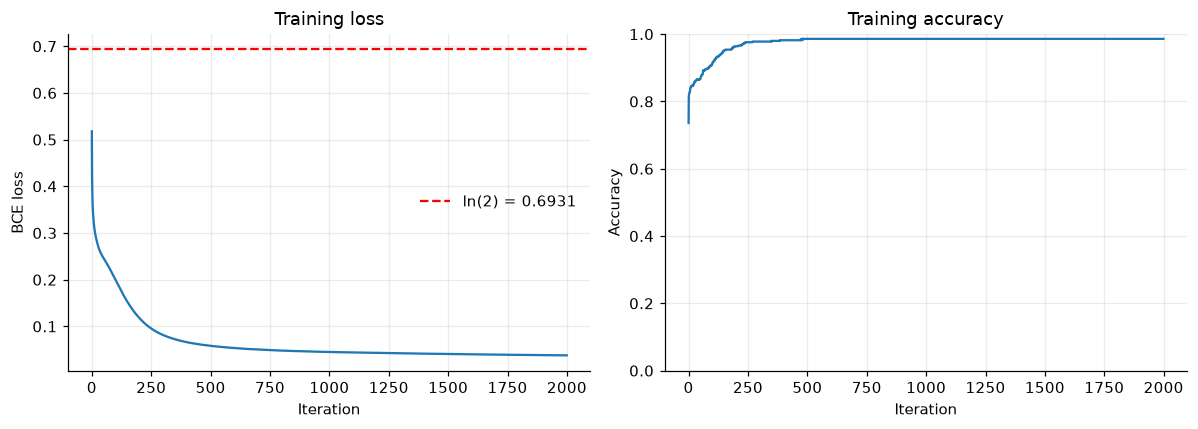

In [11]:
# ────────────────────────────────────────────────────────────────────
# 1) Two panels side by side: the loss on the left, the accuracy on the right.
# 2) Both against the iteration number. Label the axes.
# 3) Mark ln 2 = 0.6931 — the loss of a model that has learned nothing on a
#    balanced problem. Yours starts a little below it.
# Search: "matplotlib subplots two panels axhline"
# https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html
#
# ١) لوحتان جنبًا إلى جنب: الخسارة يسارًا والدقة يمينًا.
# ٢) كلتاهما مقابل رقم التكرار. وسمِّ المحاور.
# ٣) أشِر إلى `ln 2 = 0.6931` — خسارة نموذج لم يتعلّم شيئًا في مسألة متوازنة.
#    وخسارتك تبدأ تحتها بقليل.
# ابحث عن: "matplotlib subplots two panels axhline"
# ────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["iteration"], history["loss"])
axes[0].axhline(
    0.6931,
    color="red",
    linestyle="--",
    label="ln(2) = 0.6931"
)
axes[0].set_title("Training loss")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("BCE loss")
axes[0].legend()

axes[1].plot(history["iteration"], history["accuracy"])
axes[1].set_title("Training accuracy")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

The dashed line is 0.6931 — `ln 2`, the loss of a model that outputs 0.5 for everything, which is
what a network that has learned nothing scores on a balanced problem. Yours starts below it, at
about 0.52, only because these particular random weights already put 74% of the points on the right
side — yesterday's smear, measured. **Learn the 0.6931.**
On Sunday you will meet a flat curve sitting on it, and recognising it on sight will save you an hour
of tuning something that was never the problem.

Then look at the two panels together. The loss keeps falling smoothly for 2,000 iterations; the
accuracy jumps in steps and then sits still for hundreds of iterations at a time. They are measuring
different things: the loss cares how *confident* a correct answer was, and accuracy only cares which
side of 0.5 it landed. You optimise one and report the other, and that is not a compromise — it is
W3D3's slide 28 in a picture.

<div dir="rtl" align="right">

الخط المتقطّع هو ٠٫٦٩٣١ وهي `ln 2`، أي خسارة نموذج يُخرِج ٠٫٥ لكل شيء، وهي ما تسجّله شبكة لم تتعلّم
شيئًا في مسألة متوازنة. وخسارتك تبدأ تحته عند نحو ٠٫٥٢، لا لشيء إلا لأن هذه الأوزان العشوائية بعينها
تضع ٧٤٪ من النقاط في الجهة الصحيحة أصلًا — وهي لطخة الأمس مقيسةً. **احفظ الرقم ٠٫٦٩٣١.** فيوم الأحد ستلقى منحنى مسطّحًا جالسًا
عليه، ومعرفتُه من النظرة الأولى ستوفّر عليك ساعة من ضبط شيء لم يكن هو المشكلة أصلًا.

ثم انظر في اللوحتين معًا. تواصل الخسارة هبوطها الناعم ألفَي تكرار، بينما تقفز الدقة درجاتٍ ثم تجلس
ساكنة مئات التكرارات في المرة. فهما تقيسان شيئين مختلفين: الخسارة يهمّها كم كان الجواب الصحيح
**واثقًا**، والدقة لا يهمّها إلا في أي جهة من ٠٫٥ وقع. فتُحسِّن واحدة وتعرض الأخرى، وهذه ليست مساومة
بل هي الشريحة ٢٨ في صورة.

</div>


### Task 2.5 — the boundary, before and after

Yesterday's picture and today's, side by side in one figure. Same data, same architecture, same 33
numbers — 2,000 updates apart.

Then the number that makes it a result rather than a picture: fit a `LogisticRegression` on the same
500 rows and compare. A logistic regression is the best **straight** boundary that exists for this
data. If your network beats it, the boundary you drew is doing something a straight line cannot,
and that is the claim this week has been building towards.

<div dir="rtl" align="right">

### المهمة ٢٫٥ — الحدّ قبل وبعد

صورة الأمس وصورة اليوم جنبًا إلى جنب في شكل واحد. البيانات نفسها والمعمارية نفسها والأرقام الثلاثة
والثلاثون نفسها — بفارق ألفَي تحديث.

ثم الرقم الذي يجعلها نتيجة لا صورة: درّب `LogisticRegression` على الصفوف الخمسمئة نفسها وقارن.
فالانحدار اللوجستي هو أفضل حدّ **مستقيم** موجود لهذه البيانات. فإن تجاوزته شبكتك فالحدّ الذي رسمته
يفعل شيئًا لا يستطيعه خط مستقيم، وهذا هو الادعاء الذي يبنيه هذا الأسبوع.

</div>


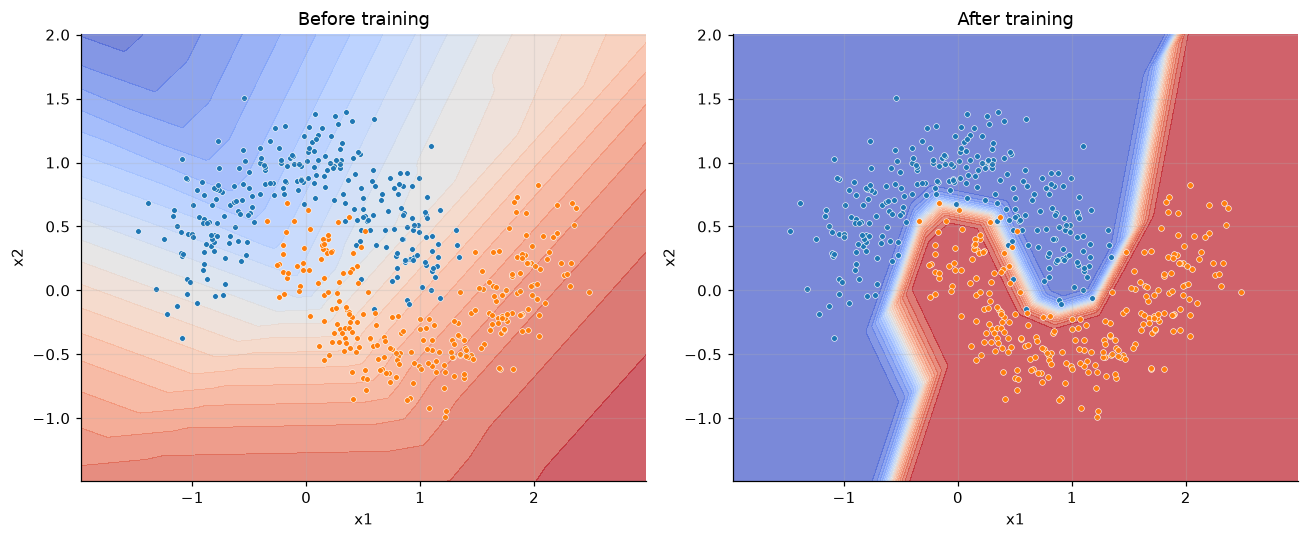

best straight boundary (logistic regression): 0.856
your network:                                 0.986
the curve is worth +0.130 of accuracy


In [12]:
# ────────────────────────────────────────────────────────────────────
# 1) Yesterday's plot_boundary, with an ax argument so two can share a figure.
#    Left panel: INITIAL_PARAMS. Right panel: the trained params.
# 2) Fit LogisticRegression on X.numpy() and y.ravel().numpy(), and score it on
#    the same rows. scikit-learn works on NumPy arrays, not tensors.
# 3) Print both accuracies and the gap. The network should be ahead by about
#    12 points; if it is level, your training loop did not train.
# Search: "matplotlib subplots share figure contourf decision boundary"
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
#
# ١) دالة `plot_boundary` من الأمس مع وسيط `ax` ليتشارك اثنان شكلًا واحدًا.
#    اللوحة اليسرى: `INITIAL_PARAMS`. واليمنى: المعاملات المُدرَّبة.
# ٢) درّب `LogisticRegression` على `X.numpy()` و`y.ravel().numpy()` وقِسه على الصفوف
#    نفسها. فـ scikit-learn يعمل على مصفوفات NumPy لا على التنسورات.
# ٣) اطبع الدقتين والفجوة. ويُتوقّع أن تتقدّم الشبكة بنحو ١٢ نقطة؛ فإن تعادلتا
#    فحلقة تدريبك لم تدرّب.
# ابحث عن: "matplotlib subplots share figure contourf decision boundary"
# ────────────────────────────────────────────────────────────────────

def plot_boundary(params, title, ax):
    """Colour the plane by the network's output, then scatter the real points."""
    pad = 0.5
    xx, yy = torch.meshgrid(
        torch.linspace(X[:, 0].min().item() - pad, X[:, 0].max().item() + pad, 200),
        torch.linspace(X[:, 1].min().item() - pad, X[:, 1].max().item() + pad, 200),
        indexing="xy")
    with torch.no_grad():   # a picture, not a computation to differentiate
        surface, _ = forward(params, torch.column_stack([xx.ravel(), yy.ravel()]))
    ax.contourf(xx, yy, surface.reshape(xx.shape), levels=20,
                cmap="coolwarm", alpha=0.7)
    for label, colour in ((0, PALETTE[0]), (1, PALETTE[1])):
        rows = y.ravel() == label
        ax.scatter(X[rows, 0], X[rows, 1], s=14, color=colour,
                   edgecolor="white", linewidth=0.4)
    ax.set_xlabel("x1")
    ax.set_title(title)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_boundary(
    INITIAL_PARAMS,
    "Before training",
    axes[0]
)

plot_boundary(
    params,
    "After training",
    axes[1]
)

axes[0].set_ylabel("x2")
axes[1].set_ylabel("x2")
plt.tight_layout()
plt.show()
logistic = LogisticRegression()
logistic.fit(
    X.numpy(),
    y.ravel().numpy()
)

linear_accuracy = logistic.score(
    X.numpy(),
    y.ravel().numpy()
)
print(f"best straight boundary (logistic regression): {linear_accuracy:.3f}")
print(f"your network:                                 {final_accuracy:.3f}")
print(f"the curve is worth {final_accuracy - linear_accuracy:+.3f} of accuracy")

## Section 3 — Stretch: measure what backpropagation saves  (≈30 min)

Open-ended. Lower expectation of completeness.

You have both implementations in front of you, so stop arguing about the cost and measure it.

Time one full `autograd_gradients()` call — a forward pass and one
`loss.backward()`. Then time a full numerical sweep — every parameter, two forward
passes each — and take the ratio. Then extrapolate: this network has 33 parameters, and a small real
network has 100,000. Multiply the measured per-parameter cost by 100,000 and report how long **one
training step** would take.

Then answer, in the cell after: at that speed, how long would 1,000 steps take, and what does that
tell you about whether the numerical method is a method at all?

<div dir="rtl" align="right">

## القسم الثالث — الإضافي: قِس ما يوفّره الانتشار الخلفي (نحو ٣٠ دقيقة)

مفتوح. والتوقّع في الإكمال أقل.

التنفيذان أمامك، فكُفَّ عن الجدال في الثمن وقِسه.

قِس زمن نداء `autograd_gradients()` كاملًا — مرور أمامي ونداء
`loss.backward()` واحد. ثم قِس زمن مسح عددي كامل — كل معامل ومرّان أماميان لكل منه — وخُذ
النسبة. ثم عمّم: في هذه الشبكة ٣٣ معاملًا، وفي شبكة حقيقية صغيرة ١٠٠٬٠٠٠. اضرب الكلفة المقيسة لكل
معامل في ١٠٠٬٠٠٠ واعرض كم تستغرق **خطوة تدريب واحدة**.

ثم أجب في الخليّة بعدها: بتلك السرعة، كم تستغرق ألف خطوة، وماذا يقول لك ذلك عن كون الطريقة العددية
طريقةً أصلًا؟

</div>


In [13]:
# ────────────────────────────────────────────────────────────────────
# 1) time.perf_counter() around each, and run the fast one several times so the
#    measurement is not dominated by timer noise.
# 2) The fast one is autograd_gradients — one forward pass and one loss.backward().
#    The numerical sweep is the loop from task 2.3 without the comparison.
# 3) Scale it: seconds per parameter x 100,000 = one step of a small real network.
#    Print it in seconds, and then in whatever unit makes it readable.
# Search: "python time.perf_counter benchmark loop"
# https://docs.python.org/3/library/time.html#time.perf_counter
#
# ١) `time.perf_counter()` حول كل واحدة، وشغّل السريعة عدة مرات كي لا تسيطر ضوضاء
#    المؤقّت على القياس.
# ٢) السريعة هي `autograd_gradients` — مرور أمامي واحد ونداء `loss.backward()` واحد.
#    والمسح العددي هو حلقة المهمة ٢٫٣ بلا المقارنة.
# ٣) عمّمها: الثواني لكل معامل × ١٠٠٬٠٠٠ = خطوة واحدة لشبكة حقيقية صغيرة. واطبعها
#    بالثواني ثم بالوحدة التي تجعلها مقروءة.
# ابحث عن: "python time.perf_counter benchmark loop"
# ────────────────────────────────────────────────────────────────────

REPEATS = 50
start = time.perf_counter()

for _ in range(REPEATS):
    autograd_gradients(params, X, y)

autograd_seconds = (time.perf_counter() - start) / REPEATS


start = time.perf_counter()

for key in ("W1", "b1", "W2", "b2"):
    for index in itertools.product(
        *(range(n) for n in params[key].shape)
    ):
        numerical_gradient(
            params, X, y, key, index, eps=1e-6
        )

numerical_seconds = time.perf_counter() - start
n_params = sum(p.numel() for p in params.values())
ratio = numerical_seconds / autograd_seconds
per_parameter = numerical_seconds / n_params
print(f"one forward + loss.backward(), all {n_params} gradients: "
      f"{autograd_seconds * 1000:.2f} ms")
print(f"the numerical sweep, all {n_params} gradients:           "
      f"{numerical_seconds * 1000:.2f} ms")
print(f"ratio: {ratio:.0f}x slower, for the same numbers")
print()
big = per_parameter * 100_000
print(f"at {per_parameter * 1000:.3f} ms per parameter, one training step of a "
      f"100,000-parameter network would cost {big:.0f} s ({big / 60:.1f} min)")
print(f"and 1,000 steps would take {big * 1000 / 3600:.1f} hours")

one forward + loss.backward(), all 33 gradients: 23.65 ms
the numerical sweep, all 33 gradients:           46.47 ms
ratio: 2x slower, for the same numbers

at 1.408 ms per parameter, one training step of a 100,000-parameter network would cost 141 s (2.3 min)
and 1,000 steps would take 39.1 hours


**Your two sentences:** _(is the numerical method slow, or is it not a method? And what is the one
thing it is still the right tool for?)_

<div dir="rtl" align="right">

**جملتاك:** _(هل الطريقة العددية بطيئة أم أنها ليست طريقة أصلًا؟ وما الشيء الوحيد الذي ما زالت هي
الأداة الصحيحة له؟)_

</div>


<div dir="rtl" align="right">

### إجابتي
- الطريقة العددية ماهي طريقة عملية في تدريب الشبكات حسب قياسي بتحتاج 1,000 خطوة اذا الشبكة فيها 100,000 معامل إلى وتقريبًا 39.1 ساعة
- لكن تبقى أداة مناسبة اننا نتأكد من صحة التدرجات ومقارنتها بنتائج autograd
</div>

## Save your artefacts

Two files, and tomorrow needs both:

- **`tensor_net_history.parquet`** — one row per iteration: the loss and the accuracy. Tomorrow you
  plot PyTorch's curve on top of this one.
- **`tensor_net_params.pt`** — the weights this run **started** from and the weights it ended with,
  saved with `torch.save` as a plain dict of tensors.
  The starting weights are the important half: tomorrow's PyTorch network is loaded with these exact
  numbers, so that when the two loss curves agree to six decimals it is because the arithmetic is the
  same, and not because two random initialisations happened to be close.

<div dir="rtl" align="right">

## احفظ مخرجاتك

ملفان، والغد يحتاج كليهما:

- **`tensor_net_history.parquet`** وفيه صف لكل تكرار: الخسارة والدقة. وغدًا ترسم منحنى PyTorch فوق
  هذا المنحنى.
- **`tensor_net_params.pt`** وفيه الأوزان التي **بدأ** منها هذا التشغيل والأوزان التي انتهى إليها،
  محفوظةً بـ `torch.save` قاموسًا عاديًا من التنسورات.
  والأوزان الابتدائية هي النصف المهمّ: فشبكة الغد بـ PyTorch تُحمَّل بهذه الأرقام بالضبط، حتى إذا
  توافق منحنيا الخسارة إلى ست خانات عشرية كان ذلك لأن الحساب واحد، لا لأن تهيئتين عشوائيتين تصادف
  تقاربهما.

</div>


In [14]:
history_path = ARTEFACT_DIR / "tensor_net_history.parquet"
history.to_parquet(history_path, index=False)

params_path = ARTEFACT_DIR / "tensor_net_params.pt"
torch.save({"init": INITIAL_PARAMS,
            "final": {k: v.detach().clone() for k, v in params.items()},
            "config": {"n_in": N_IN, "n_hidden": N_HIDDEN, "n_out": N_OUT,
                       "iterations": ITERATIONS, "lr": LR, "seed": SEED}},
           params_path)

reloaded_history = pd.read_parquet(history_path)
reloaded_params = torch.load(params_path)

print(f"Saved {history_path}")
print(f"  {len(reloaded_history):,} rows, columns {list(reloaded_history.columns)}")
print(f"  loss {reloaded_history.iloc[0]['loss']:.4f} -> "
      f"{reloaded_history.iloc[-1]['loss']:.4f}")
print(f"\nSaved {params_path}")
print(f"  init {sorted(reloaded_params['init'])}, final {sorted(reloaded_params['final'])}, "
      f"config {reloaded_params['config']}")
print(f"  the initial weights survived the round trip: "
      f"{torch.equal(reloaded_params['init']['W1'], INITIAL_PARAMS['W1'])}")

Saved c:\Users\pkupr\AIEP_Olo_student\week_3_neural_networks\labs\D3_backprop\artefacts\tensor_net_history.parquet
  2,000 rows, columns ['iteration', 'loss', 'accuracy']
  loss 0.5177 -> 0.0380

Saved c:\Users\pkupr\AIEP_Olo_student\week_3_neural_networks\labs\D3_backprop\artefacts\tensor_net_params.pt
  init ['W1', 'W2', 'b1', 'b2'], final ['W1', 'W2', 'b1', 'b2'], config {'n_in': 2, 'n_hidden': 8, 'n_out': 1, 'iterations': 2000, 'lr': 1.0, 'seed': 42}
  the initial weights survived the round trip: True


## Sanity check

Run this last. Every check that fails tells you what to fix and why.

The third one is the one that matters: it fails if **any** of your 33 gradients disagrees with its
numerical counterpart. It does not average, and it does not sample. If it passes, the gradients you train
with are correct — and you know that rather than hoping it.

<div dir="rtl" align="right">

## فحص النتائج

شغّل هذه الخليّة أخيرًا. كل فحص يفشل يخبرك بما تُصلحه ولماذا.

والفحص الثالث هو المهمّ: يفشل إن اختلف **أي** واحد من اشتقاقاتك الثلاثة والثلاثين عن نظيره العددي.
ولا يتوسّط ولا يأخذ عيّنة. فإن نجح فالاشتقاقات التي تدرّب بها صحيحة — وأنت تعرف ذلك لا ترجوه.

</div>


In [15]:
# --- Sanity checks ----------------------------------------------------------------

check(math.isclose(loss_at_1, 0.0333, abs_tol=5e-5)
      and math.isclose(loss_at_101, 0.0319, abs_tol=5e-5)
      and math.isclose(one_sided, -0.134, abs_tol=1e-3),
      f"the warm-up must reproduce the lecture: loss 0.0333 (got {loss_at_1:.4f}), "
      f"loss 0.0319 after the nudge (got {loss_at_101:.4f}), gradient -0.134 "
      f"(got {one_sided:.4f})",
      f"يجب أن تُعيد التهيئة إنتاج أرقام المحاضرة: خسارة ٠٫٠٣٣٣ (والناتج {loss_at_1:.4f})، "
      f"وخسارة ٠٫٠٣١٩ بعد التحريك (والناتج {loss_at_101:.4f})، واشتقاق ٠٫١٣٤− "
      f"(والناتج {one_sided:.4f})")

check(bool(confident_wrong > 4 * confident_right),
      f"binary cross-entropy must punish a confident wrong answer far more than a hesitant "
      f"one — 0.1 cost {confident_wrong:.4f} and 0.9 cost {confident_right:.4f}, a ratio "
      f"of {confident_wrong / confident_right:.1f}x (it should be about 22)",
      f"يجب أن تعاقب الانتروبيا التقاطعية الجواب الخطأ الواثق أشدّ بكثير من المتردّد — "
      f"فكلفة ٠٫١ هي {confident_wrong:.4f} وكلفة ٠٫٩ هي {confident_right:.4f}، بنسبة "
      f"{confident_wrong / confident_right:.1f} (والمتوقّع نحو ٢٢)")

check(len(gradient_check) == 33 and worst < 1e-6,
      f"EVERY autograd gradient must match its numerical counterpart within 1e-6 — "
      f"{len(gradient_check)} were checked and the worst disagreement was {worst:.2e}. "
      f"A single mismatch means a gradient is wrong somewhere — look for a float() in the "
      f"loss, or a .grad that was never cleared.",
      f"يجب أن يطابق **كل** اشتقاق من الاشتقاق التلقائي نظيره العددي في حدود 1e-6 — فُحص منها "
      f"{len(gradient_check)} وأسوأ اختلاف كان {worst:.2e}. واختلاف واحد يعني أن اشتقاقًا خطأ في "
      f"موضع ما — فابحث عن `float()` في الخسارة، أو `.grad` لم يُمسح.")

first_hundred = history["loss"].diff().iloc[1:101]
check(bool((first_hundred < 0).all()),
      f"the loss must fall on every one of the first 100 iterations — it rose on "
      f"{int((first_hundred >= 0).sum())} of them. A rise this early means the learning "
      f"rate is too high, a gradient has the wrong sign, or .grad is not being cleared.",
      f"يجب أن تهبط الخسارة في كل واحد من التكرارات المئة الأولى — وقد ارتفعت في "
      f"{int((first_hundred >= 0).sum())} منها. والارتفاع في هذا الوقت المبكر يعني أن معدّل "
      f"التعلّم مرتفع، أو أن إشارة اشتقاق خطأ، أو أن `.grad` لا يُمسح.")

check(0.85 < final_accuracy < 1.0,
      f"final accuracy on moons_toy should be above 0.85 and below 1.0 — got "
      f"{final_accuracy:.3f}. Exactly 1.0 would mean the noise=0.2 overlap vanished, "
      f"which is not possible on this data.",
      f"يجب أن تتجاوز الدقة النهائية على `moons_toy` قيمة ٠٫٨٥ وأن تقلّ عن ١٫٠ — والناتج "
      f"{final_accuracy:.3f}. و١٫٠ تامة تعني أن تداخل الضوضاء ٠٫٢ اختفى، وهذا غير ممكن على "
      f"هذه البيانات.")

check(final_accuracy > linear_accuracy + 0.05,
      f"the trained network must beat the best straight boundary by more than 5 points — "
      f"network {final_accuracy:.3f} vs logistic regression {linear_accuracy:.3f}. That "
      f"gap is the evidence that your boundary is genuinely non-linear.",
      f"يجب أن تتجاوز الشبكة المُدرَّبة أفضل حدّ مستقيم بأكثر من خمس نقاط — الشبكة "
      f"{final_accuracy:.3f} مقابل الانحدار اللوجستي {linear_accuracy:.3f}. وهذه الفجوة هي "
      f"الدليل على أن حدّك غير خطي فعلًا.")

check(history_path.exists() and params_path.exists()
      and len(reloaded_history) == ITERATIONS,
      f"both artefacts must be on disk with {ITERATIONS} recorded iterations — history "
      f"{history_path.exists()} with {len(reloaded_history)} rows, params "
      f"{params_path.exists()}",
      f"يجب أن يوجد الأثران على القرص وفيهما {ITERATIONS} تكرار مُسجَّل — السجلّ "
      f"{history_path.exists()} بـ {len(reloaded_history)} صفًا، والمعاملات "
      f"{params_path.exists()}")

report()

──────────────────────────────────────────────────────────────────
  ✓  the warm-up must reproduce the lecture: loss 0.0333 (got 0.0333), loss 0.0319 after the nudge (got 0.0319), gradient -0.134 (got -0.1336)
  ✓  binary cross-entropy must punish a confident wrong answer far more than a hesitant one — 0.1 cost 2.3026 and 0.9 cost 0.1054, a ratio of 21.9x (it should be about 22)
  ✓  EVERY autograd gradient must match its numerical counterpart within 1e-6 — 33 were checked and the worst disagreement was 1.09e-10. A single mismatch means a gradient is wrong somewhere — look for a float() in the loss, or a .grad that was never cleared.
  ✓  the loss must fall on every one of the first 100 iterations — it rose on 0 of them. A rise this early means the learning rate is too high, a gradient has the wrong sign, or .grad is not being cleared.
  ✓  final accuracy on moons_toy should be above 0.85 and below 1.0 — got 0.986. Exactly 1.0 would mean the noise=0.2 overlap vanished, which is not pos

## What's next

You have used autograd and, more importantly, you have **proved** its gradients correct. That second
part is the transferable skill: for the rest of your career, when you suspect a gradient, you now
know how to find out instead of guessing.

Tomorrow (**W3D4**) the rest of the hand-built machinery goes. `init_params` and `forward` become an
`nn.Module`, the update loop becomes `torch.optim.SGD`, and the full batch becomes a `DataLoader`. You
load the network with the exact weights in `tensor_net_params.pt` and confirm that its loss curve
lands on this one — then count the lines you deleted.

Two things travel with you:

- **`tensor_net_history.parquet` and `tensor_net_params.pt`** — tomorrow's comparison is only honest
  because both runs start from the same numbers.
- **The gradient check itself.** `torch.autograd.gradcheck` is the library's version of the loop you
  wrote in task 2.3, and now you know exactly what it compares.

**A3 is issued today**, due W4D2. The mark is on your architecture justification and your training
curves; the held-out score is a floor, not the grade.

<div dir="rtl" align="right">

## ماذا بعد

استخدمت الاشتقاق التلقائي، والأهمّ أنك **أثبتّ** صحّة اشتقاقاته. وهذا الجزء الثاني هو المهارة المنقولة: فبقية حياتك
المهنية، حين تشكّ في اشتقاق، صرت تعرف كيف تتأكّد بدل أن تخمّن.

وغدًا (**الأسبوع ٣ اليوم ٤**) يذهب ما بقي من الآلة المبنيّة يدويًا. فتصير `init_params` و`forward`
`nn.Module`، وتصير حلقة التحديث `torch.optim.SGD`، وتصير الدفعة الكاملة `DataLoader`. وتُحمّل الشبكة
بالأوزان التي في `tensor_net_params.pt` بالضبط وتتأكّد أن منحنى خسارتها يقع على هذا المنحنى — ثم تعدّ
الأسطر التي حذفتها.

وشيئان يسافران معك:

- **`tensor_net_history.parquet` و`tensor_net_params.pt`** — فمقارنة الغد لا تكون صادقة إلا لأن
  التشغيلين يبدآن من الأرقام نفسها.
- **فحص الاشتقاق نفسه.** فـ `torch.autograd.gradcheck` هو نسخة المكتبة من الحلقة التي كتبتها في
  المهمة ٢٫٣، وصرت تعرف بالضبط ما الذي يقارنه.

**ويُطرح التكليف الثالث اليوم** ويُسلَّم في الأسبوع الرابع اليوم الثاني. والدرجة على تبرير المعمارية
وعلى منحنيات التدريب، والنتيجة على البيانات المحجوزة أرضية لا درجة.

</div>
